In [1]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu
%pip install ultralytics opencv-python matplotlib pandas

Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install ultralytics opencv-python matplotlib pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, torch, ultralytics
print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version   :", torch.__version__)
print("CPU cores         :", os.cpu_count())
print("Running on        : CPU")

Ultralytics version: 8.4.189
PyTorch version   : 2.14.1+cpu
CPU cores         : 12
Running on        : CPU


In [4]:
DEVICE  = "cpu"
EPOCHS  = 10
IMGSZ   = 640
BATCH   = 8
WORKERS = 0

torch.set_num_threads(os.cpu_count())   # use all CPU cores

In [5]:
# ===== OPTION A: generate the dataset with code =====
"""
OrbitalIQ GeoAI Program - YOLO Demo Dataset Generator
-----------------------------------------------------
Creates a small synthetic "satellite-style" dataset in YOLO format.

Classes:
    0 = building   (roofs of different colours, with shadows)
    1 = vehicle    (small cars parked on roads)
    2 = tree       (round green canopies with shadows)

Output layout (exactly what YOLO expects):
    aerial_yolo_dataset/
        images/train  images/val  images/test
        labels/train  labels/val  labels/test
        data.yaml

Each label file has one line per object:
    class_id  x_center  y_center  width  height     (all normalised 0-1)
"""
import os
import random
import numpy as np
import cv2

CLASSES = ["building", "vehicle", "tree"]
IMG_SIZE = 640

ROOF_COLOURS = [  # BGR
    (60, 60, 170), (70, 90, 190), (200, 200, 205), (175, 180, 185),
    (140, 120, 90), (90, 110, 120), (210, 190, 150), (80, 80, 80),
]
CAR_COLOURS = [(240, 240, 240), (30, 30, 30), (40, 40, 200), (180, 90, 30),
               (150, 150, 150), (30, 150, 220)]


def make_background(rng):
    """Soil / grass texture made from smoothed random noise."""
    base = np.array(random.choice([(70, 110, 95), (80, 120, 120), (65, 100, 80),
                                   (95, 130, 140)]), np.float32)
    img = np.ones((IMG_SIZE, IMG_SIZE, 3), np.float32) * base
    for k, amp in [(81, 16), (21, 10), (3, 8)]:
        noise = rng.normal(0, 1, (IMG_SIZE, IMG_SIZE)).astype(np.float32)
        noise = cv2.GaussianBlur(noise, (k, k), 0)
        noise = noise / (noise.std() + 1e-6) * amp
        img += noise[..., None]
    return img


def draw_roads(img, rng):
    """Draws 1-3 straight roads and returns their centre lines."""
    roads = []
    for _ in range(rng.integers(1, 4)):
        w = int(rng.integers(26, 40))
        if rng.random() < 0.5:   # horizontal
            y = int(rng.integers(60, IMG_SIZE - 60))
            cv2.rectangle(img, (0, y - w // 2), (IMG_SIZE, y + w // 2), (105, 105, 108), -1)
            cv2.line(img, (0, y), (IMG_SIZE, y), (190, 190, 190), 1)
            roads.append(("h", y, w))
        else:                    # vertical
            x = int(rng.integers(60, IMG_SIZE - 60))
            cv2.rectangle(img, (x - w // 2, 0), (x + w // 2, IMG_SIZE), (105, 105, 108), -1)
            cv2.line(img, (x, 0), (x, IMG_SIZE), (190, 190, 190), 1)
            roads.append(("v", x, w))
    return roads


def overlaps(box, boxes, pad=4):
    x1, y1, x2, y2 = box
    for a1, b1, a2, b2 in boxes:
        if x1 < a2 + pad and x2 + pad > a1 and y1 < b2 + pad and y2 + pad > b1:
            return True
    return False


def on_road(box, roads):
    x1, y1, x2, y2 = box
    for d, c, w in roads:
        if d == "h" and y1 < c + w // 2 + 3 and y2 > c - w // 2 - 3:
            return True
        if d == "v" and x1 < c + w // 2 + 3 and x2 > c - w // 2 - 3:
            return True
    return False


def add_building(img, rng, occupied, roads):
    for _ in range(40):
        w, h = int(rng.integers(30, 95)), int(rng.integers(30, 95))
        x1, y1 = int(rng.integers(5, IMG_SIZE - w - 5)), int(rng.integers(5, IMG_SIZE - h - 5))
        box = (x1, y1, x1 + w, y1 + h)
        if overlaps(box, occupied, 8) or on_road(box, roads):
            continue
        sh = int(rng.integers(4, 9))  # shadow towards bottom-right
        cv2.rectangle(img, (x1 + sh, y1 + sh), (x1 + w + sh, y1 + h + sh), (35, 45, 40), -1)
        col = np.array(random.choice(ROOF_COLOURS), np.float32)
        cv2.rectangle(img, (x1, y1), (x1 + w, y1 + h), col.tolist(), -1)
        # gable roof: one half slightly darker
        if rng.random() < 0.6:
            if w > h:
                cv2.rectangle(img, (x1, y1 + h // 2), (x1 + w, y1 + h), (col * 0.82).tolist(), -1)
            else:
                cv2.rectangle(img, (x1 + w // 2, y1), (x1 + w, y1 + h), (col * 0.82).tolist(), -1)
        cv2.rectangle(img, (x1, y1), (x1 + w, y1 + h), (col * 0.6).tolist(), 1)
        occupied.append(box)
        return box
    return None


def add_vehicle(img, rng, occupied, roads):
    if not roads:
        return None
    for _ in range(40):
        d, c, w = roads[rng.integers(len(roads))]
        L, W = int(rng.integers(14, 20)), int(rng.integers(7, 10))
        lane = c + (w // 4 if rng.random() < 0.5 else -w // 4)
        if d == "h":
            x1 = int(rng.integers(5, IMG_SIZE - L - 5))
            box = (x1, lane - W // 2, x1 + L, lane + W // 2)
        else:
            y1 = int(rng.integers(5, IMG_SIZE - L - 5))
            box = (lane - W // 2, y1, lane + W // 2, y1 + L)
        if overlaps(box, occupied, 3):
            continue
        x1, y1, x2, y2 = box
        col = random.choice(CAR_COLOURS)
        cv2.rectangle(img, (x1 + 2, y1 + 2), (x2 + 2, y2 + 2), (50, 50, 50), -1)
        cv2.rectangle(img, (x1, y1), (x2, y2), col, -1)
        # windscreen
        if d == "h":
            cv2.rectangle(img, (x1 + L // 3, y1 + 1), (x1 + L // 3 + 3, y2 - 1), (60, 50, 40), -1)
        else:
            cv2.rectangle(img, (x1 + 1, y1 + L // 3), (x2 - 1, y1 + L // 3 + 3), (60, 50, 40), -1)
        occupied.append(box)
        return box
    return None


def add_tree(img, rng, occupied, roads):
    for _ in range(40):
        r = int(rng.integers(9, 22))
        cx, cy = int(rng.integers(r + 5, IMG_SIZE - r - 5)), int(rng.integers(r + 5, IMG_SIZE - r - 5))
        box = (cx - r, cy - r, cx + r, cy + r)
        if overlaps(box, occupied, 2) or on_road(box, roads):
            continue
        cv2.circle(img, (cx + r // 3, cy + r // 3), r, (25, 40, 30), -1)          # shadow
        g = int(rng.integers(90, 140))
        cv2.circle(img, (cx, cy), r, (30, g, 40), -1)                              # canopy
        cv2.circle(img, (cx - r // 4, cy - r // 4), max(2, r // 2), (45, g + 40, 60), -1)  # sunlit
        occupied.append(box)
        return box
    return None


def make_image(seed):
    rng = np.random.default_rng(seed)
    random.seed(seed)
    img = make_background(rng)
    roads = draw_roads(img, rng)
    occupied, labels = [], []
    makers = [(0, add_building, rng.integers(4, 12)),
              (1, add_vehicle, rng.integers(2, 9)),
              (2, add_tree, rng.integers(4, 15))]
    for cls, fn, n in makers:
        for _ in range(int(n)):
            box = fn(img, rng, occupied, roads)
            if box:
                labels.append((cls, box))
    # mild sensor blur + noise so it looks less "drawn"
    img = cv2.GaussianBlur(img, (3, 3), 0)
    img += rng.normal(0, 4, img.shape).astype(np.float32)
    img = np.clip(img, 0, 255).astype(np.uint8)
    return img, labels


def to_yolo(box):
    x1, y1, x2, y2 = box
    return ((x1 + x2) / 2 / IMG_SIZE, (y1 + y2) / 2 / IMG_SIZE,
            (x2 - x1) / IMG_SIZE, (y2 - y1) / IMG_SIZE)


def build_dataset(root="aerial_yolo_dataset", n_train=200, n_val=50, n_test=10):
    splits = {"train": n_train, "val": n_val, "test": n_test}
    seed = 0
    for split, n in splits.items():
        os.makedirs(f"{root}/images/{split}", exist_ok=True)
        os.makedirs(f"{root}/labels/{split}", exist_ok=True)
        for i in range(n):
            img, labels = make_image(seed)
            seed += 1
            name = f"tile_{split}_{i:04d}"
            cv2.imwrite(f"{root}/images/{split}/{name}.jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 92])
            with open(f"{root}/labels/{split}/{name}.txt", "w") as f:
                for cls, box in labels:
                    xc, yc, w, h = to_yolo(box)
                    f.write(f"{cls} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")
    with open(f"{root}/data.yaml", "w") as f:
        abs_root = os.path.abspath(root).replace("\\", "/")   # forward slashes work on Windows too
        f.write(f"path: '{abs_root}'\n")
        f.write("train: images/train\nval: images/val\ntest: images/test\n\n")
        f.write(f"nc: {len(CLASSES)}\n")
        f.write("names:\n")
        for i, c in enumerate(CLASSES):
            f.write(f"  {i}: {c}\n")
    print(f"Dataset ready in '{root}':", splits)


build_dataset()   # 200 train / 50 val / 10 test tiles

Dataset ready in 'aerial_yolo_dataset': {'train': 200, 'val': 50, 'test': 10}


In [6]:
# ===== OPTION B: use the zip file instead (skip if you ran Option A) =====
# import zipfile, os, re
# zipfile.ZipFile("aerial_yolo_dataset.zip").extractall(".")
# # the yaml must point at the folder's real location on YOUR computer
# root = os.path.abspath("aerial_yolo_dataset").replace("\\", "/")
# y = open("aerial_yolo_dataset/data.yaml").read()
# y = re.sub(r"^path:.*$", f"path: '{root}'", y, flags=re.M)
# open("aerial_yolo_dataset/data.yaml", "w").write(y)
# print(y)

In [7]:
import os, glob
DATA = "aerial_yolo_dataset"
for split in ["train", "val", "test"]:
    n_img = len(glob.glob(f"{DATA}/images/{split}/*.jpg"))
    n_lbl = len(glob.glob(f"{DATA}/labels/{split}/*.txt"))
    print(f"{split:5s}: {n_img} images | {n_lbl} label files")

print("\n----- data.yaml -----")
print(open(f"{DATA}/data.yaml").read())

train: 200 images | 200 label files
val  : 50 images | 50 label files
test : 10 images | 10 label files

----- data.yaml -----
path: 'C:/Users/aafir/OneDrive/Documents/Geo AI/Day_29_yolo/aerial_yolo_dataset'
train: images/train
val: images/val
test: images/test

nc: 3
names:
  0: building
  1: vehicle
  2: tree



In [8]:
sample = sorted(glob.glob(f"{DATA}/labels/train/*.txt"))[0]
print("File:", sample, "\n")
lines = open(sample).read().strip().split("\n")
for line in lines[:8]:
    print(line)
print(f"... {len(lines)} objects in this tile")

# Convert the first line back to pixels
c, xc, yc, w, h = map(float, lines[0].split())
W = H = 640
print(f"\nFirst object → class {int(c)}, pixel box: "
      f"x1={int((xc-w/2)*W)}, y1={int((yc-h/2)*H)}, x2={int((xc+w/2)*W)}, y2={int((yc+h/2)*H)}")

File: aerial_yolo_dataset/labels/train\tile_train_0000.txt 

0 0.315625 0.442969 0.056250 0.142187
0 0.136719 0.766406 0.126562 0.126562
0 0.482812 0.921094 0.100000 0.048438
0 0.128125 0.160156 0.137500 0.123438
1 0.604688 0.021875 0.009375 0.021875
1 0.579688 0.621094 0.012500 0.029687
1 0.396875 0.094531 0.012500 0.023438
1 0.396875 0.932813 0.009375 0.025000
... 23 objects in this tile

First object → class 0, pixel box: x1=184, y1=238, x2=220, y2=329


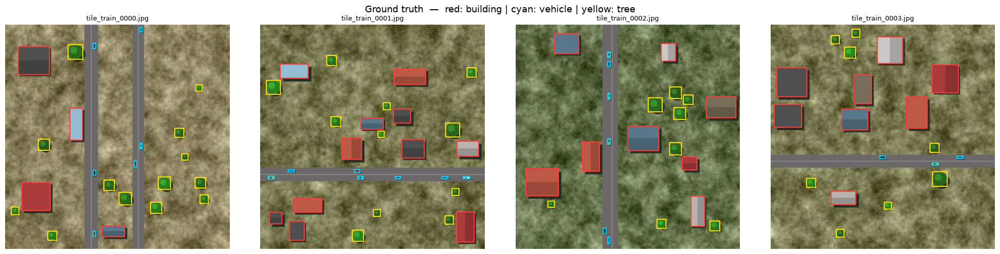

In [9]:
import cv2, matplotlib.pyplot as plt

CLASS_NAMES = ["building", "vehicle", "tree"]
COLOURS = [(255, 60, 60), (0, 220, 255), (255, 230, 0)]   # RGB

def show_ground_truth(img_path, ax):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    lbl = img_path.replace("images", "labels").replace(".jpg", ".txt")
    for line in open(lbl):
        c, xc, yc, w, h = map(float, line.split())
        c = int(c)
        x1, y1 = int((xc - w/2) * W), int((yc - h/2) * H)
        x2, y2 = int((xc + w/2) * W), int((yc + h/2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), COLOURS[c], 2)
    ax.imshow(img); ax.axis("off"); ax.set_title(os.path.basename(img_path), fontsize=9)

paths = sorted(glob.glob(f"{DATA}/images/train/*.jpg"))[:4]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for p, ax in zip(paths, axes):
    show_ground_truth(p, ax)
plt.suptitle("Ground truth  —  red: building | cyan: vehicle | yellow: tree", fontsize=13)
plt.tight_layout(); plt.show()

          objects  avg_area_px
building     1487         3690
vehicle       974          121
tree         1798          929


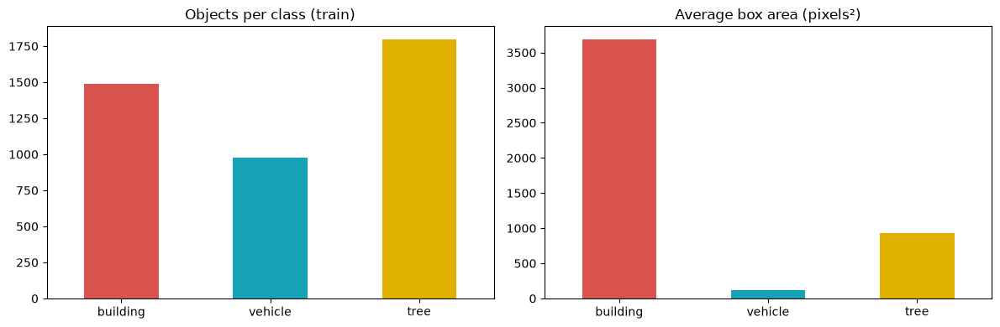

In [10]:
import collections, pandas as pd

counts = collections.Counter()
sizes = collections.defaultdict(list)
for f in glob.glob(f"{DATA}/labels/train/*.txt"):
    for line in open(f):
        c, _, _, w, h = map(float, line.split())
        counts[CLASS_NAMES[int(c)]] += 1
        sizes[CLASS_NAMES[int(c)]].append(w * h * 640 * 640)

df = pd.DataFrame({"objects": counts,
                   "avg_area_px": {k: round(sum(v)/len(v)) for k, v in sizes.items()}})
print(df)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["objects"].plot.bar(ax=ax[0], color=["#d9534f", "#17a2b8", "#e0b000"], title="Objects per class (train)")
df["avg_area_px"].plot.bar(ax=ax[1], color=["#d9534f", "#17a2b8", "#e0b000"], title="Average box area (pixels²)")
for a in ax: a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [12]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")   # or yolo11n.pt, yolov8s.pt, etc. (whichever your notebook uses)

In [13]:
from ultralytics import YOLO
import torch

DATA    = "aerial_yolo_dataset"            # folder containing data.yaml
EPOCHS  = 50
IMGSZ   = 640
BATCH   = 16
DEVICE  = 0 if torch.cuda.is_available() else "cpu"
WORKERS = 2

model = YOLO("yolov8n.pt")

In [14]:
results = model.train(
    data=f"{DATA}/data.yaml",
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    workers=WORKERS,
    patience=5,
    project="runs",
    name="aerial_yolo",
    exist_ok=True,
    plots=True,
)
RUN = str(model.trainer.save_dir)      # folder where weights, plots and logs were saved
print("Results saved in:", RUN)

New https://pypi.org/project/ultralytics/8.4.190 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.13.15 torch-2.14.1+cpu CPU (AMD Ryzen 7 7445HS w/ Radeon 740M Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=aerial_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=y

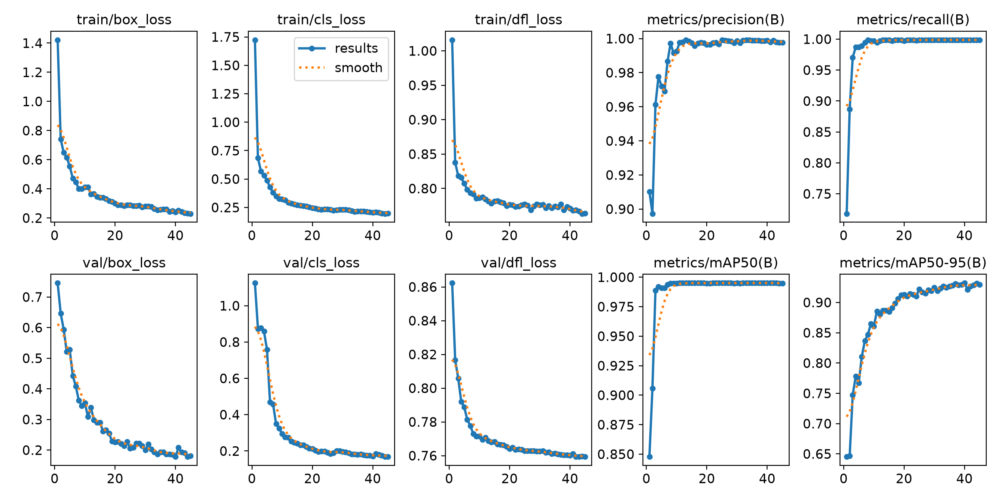

In [15]:
from IPython.display import Image, display
display(Image(f"{RUN}/results.png", width=1000))

In [16]:
best = YOLO(f"{RUN}/weights/best.pt")
metrics = best.val(data=f"{DATA}/data.yaml", split="val", imgsz=IMGSZ, batch=BATCH,
                   device=DEVICE, workers=WORKERS, plots=True)

rows = []
for i, name in enumerate(CLASS_NAMES):
    p, r, ap50, ap = metrics.box.class_result(i)
    rows.append([name, round(p, 3), round(r, 3), round(ap50, 3), round(ap, 3)])
table = pd.DataFrame(rows, columns=["class", "precision", "recall", "mAP50", "mAP50-95"])
print(table.to_string(index=False))
print(f"\nOverall  mAP50 = {metrics.box.map50:.3f}   |   mAP50-95 = {metrics.box.map:.3f}")

Ultralytics 8.4.189  Python-3.13.15 torch-2.14.1+cpu CPU (AMD Ryzen 7 7445HS w/ Radeon 740M Graphics)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 286.7±131.0 MB/s, size: 106.5 KB)
val: Scanning C:\Users\aafir\OneDrive\Documents\Geo AI\Day_29_yolo\aerial_yolo_dataset\labels\val.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 19.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.2it/s 3.5s1.6s
                   all         50       1019      0.999      0.999      0.995      0.932
              building         50        335      0.999          1      0.995      0.995
               vehicle         50        255      0.999      0.996      0.995      0.808
                  tree         50        429      0.999          1      0.995      0.993
Speed: 2.1ms preprocess, 49.1ms inference, 0.0ms loss, 0.4ms postpr

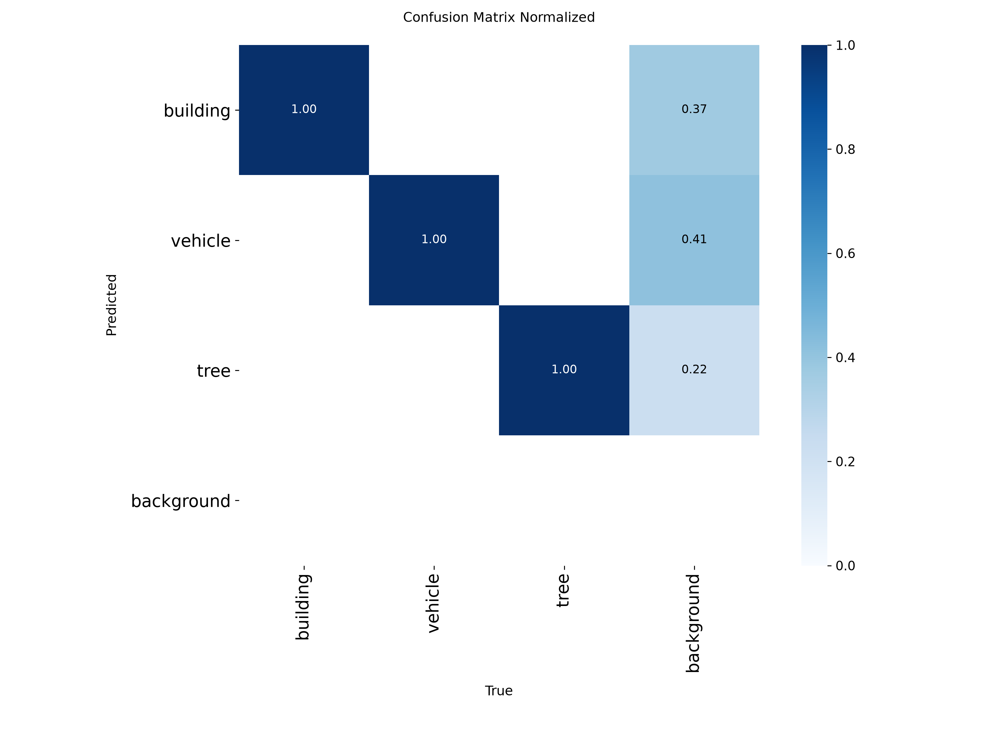

In [17]:
display(Image(f"{metrics.save_dir}/confusion_matrix_normalized.png", width=600))


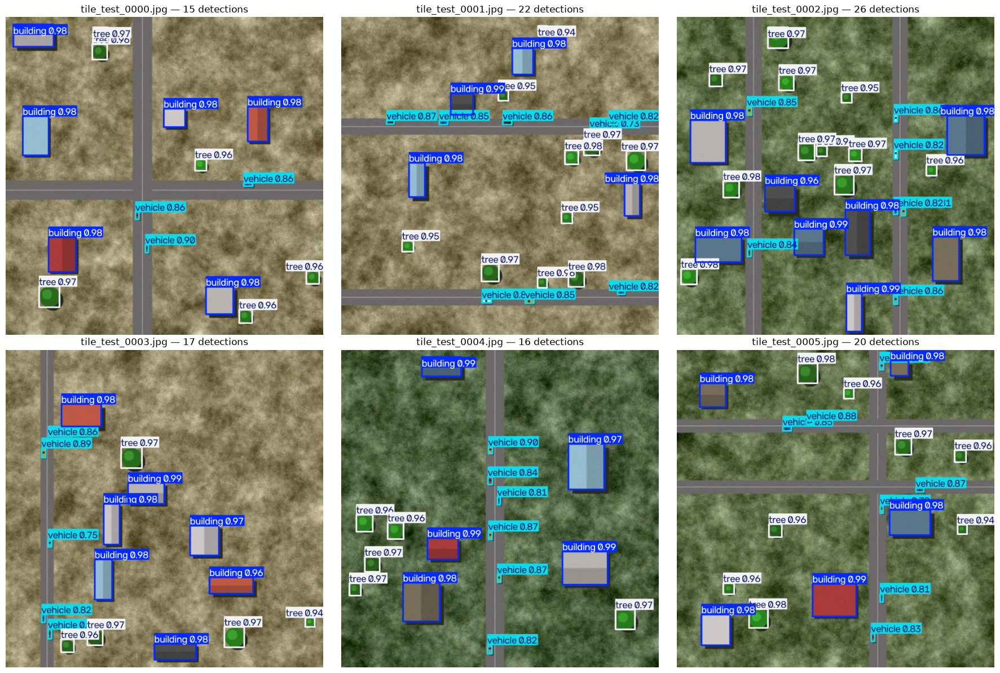

In [18]:
test_imgs = sorted(glob.glob(f"{DATA}/images/test/*.jpg"))
preds = best.predict(test_imgs, conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for r, ax in zip(preds[:6], axes.ravel()):
    ax.imshow(r.plot(line_width=2, font_size=10)[..., ::-1])   # BGR → RGB
    ax.set_title(f"{os.path.basename(r.path)} — {len(r.boxes)} detections")
    ax.axis("off")
plt.tight_layout(); plt.show()

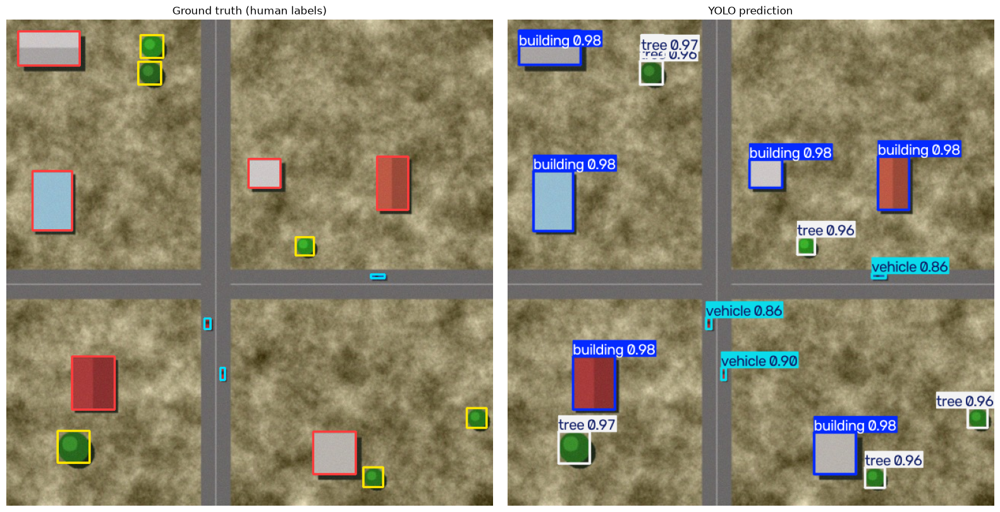

In [19]:
r = preds[0]
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
show_ground_truth(r.path, ax[0]); ax[0].set_title("Ground truth (human labels)")
ax[1].imshow(r.plot(line_width=2)[..., ::-1]); ax[1].axis("off"); ax[1].set_title("YOLO prediction")
plt.tight_layout(); plt.show()

In [20]:
records = []
for r in preds:
    cls = r.boxes.cls.cpu().numpy().astype(int)
    xywh = r.boxes.xywh.cpu().numpy()
    areas = xywh[:, 2] * xywh[:, 3]
    tile_area = r.orig_shape[0] * r.orig_shape[1]
    records.append({
        "tile": os.path.basename(r.path),
        "buildings": int((cls == 0).sum()),
        "vehicles": int((cls == 1).sum()),
        "trees": int((cls == 2).sum()),
        "built_up_%": round(100 * areas[cls == 0].sum() / tile_area, 1),
        "canopy_%": round(100 * areas[cls == 2].sum() / tile_area, 1),
    })
summary = pd.DataFrame(records)
summary

,tile,buildings,vehicles,trees,built_up_%,canopy_%
0,tile_test_0000.jpg,6,3,6,4.7,1.3
1,tile_test_0001.jpg,4,8,10,2.0,1.9
2,tile_test_0002.jpg,8,7,11,8.5,2.5
3,tile_test_0003.jpg,7,5,5,5.2,1.3
4,tile_test_0004.jpg,5,6,5,5.9,1.3
5,tile_test_0005.jpg,5,7,8,4.2,1.6
6,tile_test_0006.jpg,7,3,10,8.8,2.2
7,tile_test_0007.jpg,10,5,7,9.0,1.1
8,tile_test_0008.jpg,6,6,5,4.1,1.4
9,tile_test_0009.jpg,11,3,6,8.7,1.3


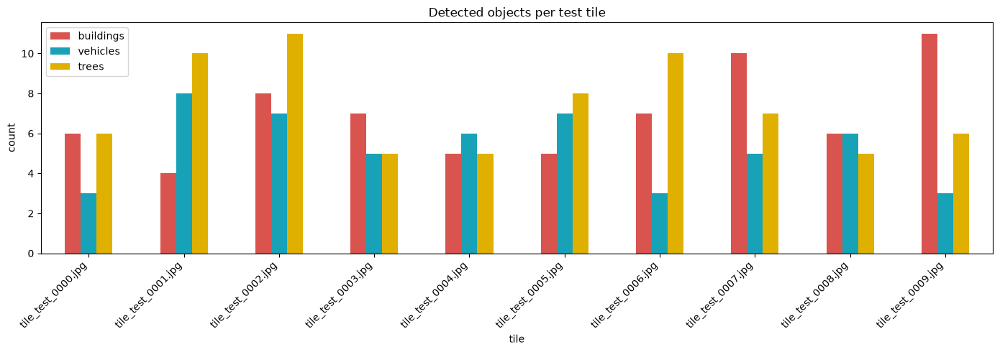

Saved tile_object_counts.csv


In [21]:
summary.set_index("tile")[["buildings", "vehicles", "trees"]].plot.bar(
    figsize=(14, 5), color=["#d9534f", "#17a2b8", "#e0b000"], title="Detected objects per test tile")
plt.xticks(rotation=45, ha="right"); plt.ylabel("count"); plt.tight_layout(); plt.show()

summary.to_csv("tile_object_counts.csv", index=False)
print("Saved tile_object_counts.csv")

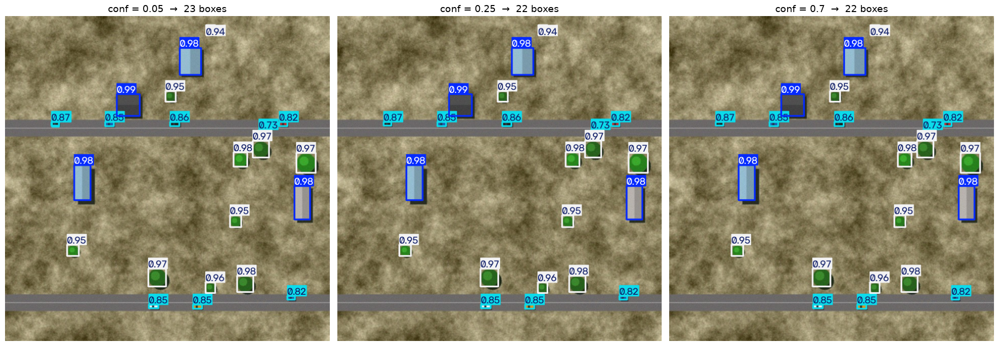

In [22]:
img = test_imgs[1]
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for conf, ax in zip([0.05, 0.25, 0.70], axes):
    r = best.predict(img, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    ax.imshow(r.plot(line_width=2, labels=False)[..., ::-1])
    ax.set_title(f"conf = {conf}  →  {len(r.boxes)} boxes", fontsize=14); ax.axis("off")
plt.tight_layout(); plt.show()

In [23]:
import shutil
shutil.copy(f"{RUN}/weights/best.pt", "aerial_yolo_best.pt")
print("Model saved as:", os.path.abspath("aerial_yolo_best.pt"))
print("Counts saved as:", os.path.abspath("tile_object_counts.csv"))

Model saved as: C:\Users\aafir\OneDrive\Documents\Geo AI\Day_29_yolo\aerial_yolo_best.pt
Counts saved as: C:\Users\aafir\OneDrive\Documents\Geo AI\Day_29_yolo\tile_object_counts.csv


In [24]:
import time
from ultralytics import YOLO

results_log = []

def run_experiment(weights, epochs, imgsz, name):
    m = YOLO(weights)
    t0 = time.time()
    m.train(data=f"{DATA}/data.yaml", epochs=epochs, imgsz=imgsz, batch=BATCH,
            device=DEVICE, workers=WORKERS, patience=5,
            project="runs", name=name, exist_ok=True, plots=False, verbose=False)
    total = time.time() - t0

    ev = YOLO(f"{m.trainer.save_dir}/weights/best.pt")
    mt = ev.val(data=f"{DATA}/data.yaml", split="val", imgsz=imgsz, batch=BATCH,
                device=DEVICE, workers=WORKERS, plots=False, verbose=False)

    row = {
        "experiment": name,
        "model": weights,
        "epochs": epochs,
        "imgsz": imgsz,
        "mAP50": round(mt.box.map50, 3),
        "mAP50-95": round(mt.box.map, 3),
        "vehicle_mAP50": round(mt.box.class_result(1)[2], 3),
        "total_min": round(total / 60, 1),
        "min_per_epoch": round(total / 60 / epochs, 2),
    }
    results_log.append(row)
    return row

In [25]:
for ep in [3, 20]:
    print(run_experiment("yolo11n.pt", epochs=ep, imgsz=IMGSZ, name=f"exp_epochs_{ep}"))

pd.DataFrame(results_log)

New https://pypi.org/project/ultralytics/8.4.190 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.13.15 torch-2.14.1+cpu CPU (AMD Ryzen 7 7445HS w/ Radeon 740M Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=aerial_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yo

,experiment,model,epochs,imgsz,mAP50,mAP50-95,vehicle_mAP50,total_min,min_per_epoch
0,exp_epochs_3,yolo11n.pt,3,640,0.993,0.747,0.990,3.3,1.12
1,exp_epochs_20,yolo11n.pt,20,640,0.995,0.914,0.995,21.1,1.05


In [26]:
for w in ["yolo11n.pt", "yolo11s.pt"]:
    tag = w.replace(".pt", "")
    print(run_experiment(w, epochs=EPOCHS, imgsz=IMGSZ, name=f"exp_model_{tag}"))

pd.DataFrame(results_log)[lambda d: d["experiment"].str.startswith("exp_model")]

New https://pypi.org/project/ultralytics/8.4.190 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.13.15 torch-2.14.1+cpu CPU (AMD Ryzen 7 7445HS w/ Radeon 740M Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=aerial_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=y

,experiment,model,epochs,imgsz,mAP50,mAP50-95,vehicle_mAP50,total_min,min_per_epoch
2,exp_model_yolo11n,yolo11n.pt,50,640,0.995,0.931,0.995,34.9,0.70
3,exp_model_yolo11s,yolo11s.pt,50,640,0.995,0.967,0.995,237.0,4.74


In [27]:
print(run_experiment("yolo11n.pt", epochs=EPOCHS, imgsz=320, name="exp_imgsz_320"))

pd.DataFrame(results_log)[lambda d: d["experiment"].isin(["exp_imgsz_320", "exp_model_yolo11n"])]

New https://pypi.org/project/ultralytics/8.4.191 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.189  Python-3.13.15 torch-2.14.1+cpu CPU (AMD Ryzen 7 7445HS w/ Radeon 740M Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=aerial_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=y

,experiment,model,epochs,imgsz,mAP50,mAP50-95,vehicle_mAP50,total_min,min_per_epoch
2,exp_model_yolo11n,yolo11n.pt,50,640,0.995,0.931,0.995,34.9,0.70
4,exp_imgsz_320,yolo11n.pt,50,320,0.951,0.764,0.864,8.4,0.17


,tile,buildings,built_up_%
7,tile_test_0007.jpg,10,9.0
6,tile_test_0006.jpg,7,8.8
9,tile_test_0009.jpg,11,8.7
2,tile_test_0002.jpg,8,8.5
4,tile_test_0004.jpg,5,5.9
3,tile_test_0003.jpg,7,5.2
0,tile_test_0000.jpg,6,4.7
5,tile_test_0005.jpg,5,4.2
8,tile_test_0008.jpg,6,4.1
1,tile_test_0001.jpg,4,2.0



Highest built-up: tile_test_0007.jpg  →  9.0% (10 buildings)


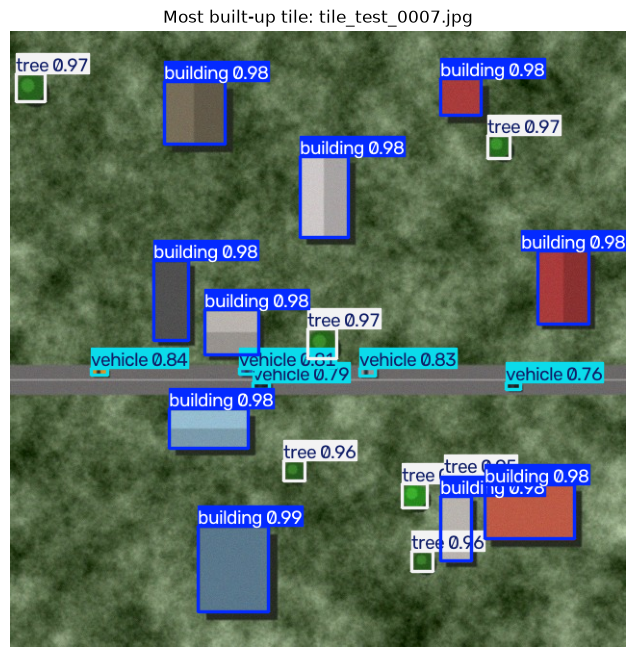

In [28]:
top = summary.sort_values("built_up_%", ascending=False)
display(top[["tile", "buildings", "built_up_%"]])

best_tile = top.iloc[0]
print(f"\nHighest built-up: {best_tile['tile']}  →  {best_tile['built_up_%']}% "
      f"({best_tile['buildings']} buildings)")

# Show it
r = next(p for p in preds if os.path.basename(p.path) == best_tile["tile"])
plt.figure(figsize=(8, 8))
plt.imshow(r.plot(line_width=2)[..., ::-1]); plt.axis("off")
plt.title(f"Most built-up tile: {best_tile['tile']}"); plt.show()

In [30]:
import geopandas as gpd
import rasterio
from rasterio.windows import from_bounds
from shapely.geometry import box as shp_box

def footprints_to_yolo(tile_tif, footprints_file, out_dir, class_id=0, tile_px=640, name="cartosat_tile"):
    os.makedirs(f"{out_dir}/images", exist_ok=True)
    os.makedirs(f"{out_dir}/labels", exist_ok=True)

    gdf = gpd.read_file(footprints_file)
    with rasterio.open(tile_tif) as src:
        gdf = gdf.to_crs(src.crs)
        W, H = src.width, src.height
        tile_bounds = shp_box(*src.bounds)
        gdf = gdf[gdf.intersects(tile_bounds)]

        # Save the tile as a 3-band JPG for YOLO
        rgb = src.read([1, 2, 3]).transpose(1, 2, 0)
        rgb = cv2.normalize(rgb, None, 0, 255, cv2.NORM_MINMAX).astype("uint8")
        cv2.imwrite(f"{out_dir}/images/{name}.jpg", cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))

        lines = []
        for geom in gdf.geometry:
            minx, miny, maxx, maxy = geom.intersection(tile_bounds).bounds
            # world → pixel coordinates
            c1, r1 = ~src.transform * (minx, maxy)   # top-left
            c2, r2 = ~src.transform * (maxx, miny)   # bottom-right
            xc, yc = (c1 + c2) / 2 / W, (r1 + r2) / 2 / H
            w, h = abs(c2 - c1) / W, abs(r2 - r1) / H
            lines.append(f"{class_id} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")

    open(f"{out_dir}/labels/{name}.txt", "w").write("\n".join(lines))
    print(f"{len(lines)} building boxes written for {name}")

# Example (change the file names to yours):
# footprints_to_yolo("cartosat3_tile.tif", "building_footprints.geojson", "my_real_dataset")